In [3]:

import os
import pandas as pd
import numpy as np

DATA_PATH = "../data/raw/application_train.csv"
DESC_PATH = "../data/raw/HomeCredit_columns_description.csv"

print("=" * 60)
print("RISKAEGIS - DATASET INSPECTION")
print("=" * 60)

# 1. Verify files
assert os.path.exists(DATA_PATH), f"Missing: {DATA_PATH}"
assert os.path.exists(DESC_PATH), f"Missing: {DESC_PATH}"

print("\nFiles found successfully.")

# 2. Inspect sample and columns
sample = pd.read_csv(DATA_PATH, nrows=5)

print("\nFirst five records:")
display(sample)

print("\nTotal columns:", len(sample.columns))
print("\nColumn names:")
print(sample.columns.tolist())

# 3. Inspect applicant IDs and target in one pass
print("\nScanning complete dataset in chunks...")

total_rows = 0
missing_ids = 0
duplicate_ids = 0
unique_ids = set()
target_counts = {}

for chunk in pd.read_csv(
    DATA_PATH,
    usecols=["SK_ID_CURR", "TARGET"],
    chunksize=50000
):
    total_rows += len(chunk)

    missing_ids += chunk["SK_ID_CURR"].isna().sum()

    # Count unique IDs across chunks
    current_ids = set(chunk["SK_ID_CURR"].dropna().unique())
    duplicate_ids += len(current_ids.intersection(unique_ids))
    unique_ids.update(current_ids)

    counts = chunk["TARGET"].value_counts(dropna=False)
    for label, count in counts.items():
        target_counts[label] = target_counts.get(label, 0) + count

    print(f"Processed {total_rows:,} records...", flush=True)

# 4. Display results
print("\n" + "=" * 60)
print("DATASET VERIFICATION RESULTS")
print("=" * 60)

print("Total records:", f"{total_rows:,}")
print("Unique applicant IDs:", f"{len(unique_ids):,}")
print("Missing applicant IDs:", missing_ids)
print("Duplicate applicant IDs:", duplicate_ids)

print("\nTarget distribution:")
target_result = pd.Series(target_counts)
print(target_result)

print("\nTarget percentages:")
print((target_result / total_rows * 100).round(2))

# 5. Inspect descriptions
description = pd.read_csv(DESC_PATH)

print("\nDescription dimensions:", description.shape)
display(description.head(10))

print("\nDataset inspection completed.")


RISKAEGIS - DATASET INSPECTION

Files found successfully.

First five records:


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,...,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,...,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0



Total columns: 122

Column names:
['SK_ID_CURR', 'TARGET', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY', 'CNT_CHILDREN', 'AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY', 'AMT_GOODS_PRICE', 'NAME_TYPE_SUITE', 'NAME_INCOME_TYPE', 'NAME_EDUCATION_TYPE', 'NAME_FAMILY_STATUS', 'NAME_HOUSING_TYPE', 'REGION_POPULATION_RELATIVE', 'DAYS_BIRTH', 'DAYS_EMPLOYED', 'DAYS_REGISTRATION', 'DAYS_ID_PUBLISH', 'OWN_CAR_AGE', 'FLAG_MOBIL', 'FLAG_EMP_PHONE', 'FLAG_WORK_PHONE', 'FLAG_CONT_MOBILE', 'FLAG_PHONE', 'FLAG_EMAIL', 'OCCUPATION_TYPE', 'CNT_FAM_MEMBERS', 'REGION_RATING_CLIENT', 'REGION_RATING_CLIENT_W_CITY', 'WEEKDAY_APPR_PROCESS_START', 'HOUR_APPR_PROCESS_START', 'REG_REGION_NOT_LIVE_REGION', 'REG_REGION_NOT_WORK_REGION', 'LIVE_REGION_NOT_WORK_REGION', 'REG_CITY_NOT_LIVE_CITY', 'REG_CITY_NOT_WORK_CITY', 'LIVE_CITY_NOT_WORK_CITY', 'ORGANIZATION_TYPE', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3', 'APARTMENTS_AVG', 'BASEMENTAREA_AVG', 'YEARS_BEGINEXPLUATATION_AVG', 'YEARS

UnicodeDecodeError: 'utf-8' codec can't decode byte 0x85 in position 59: invalid start byte

In [2]:
import sys
import pandas as pd
import numpy as np

print("Python:", sys.executable)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: c:\Users\Pardh\RiskAegis\venv\Scripts\python.exe
Pandas: 3.1.1
NumPy: 2.5.5


In [4]:
import pandas as pd
from pathlib import Path

# Dataset path
DATA_PATH = Path("../data/raw/application_train.csv")

print("=" * 60)
print("RISKAEGIS - DATASET VALIDATION")
print("=" * 60)

# Read only the applicant ID and target columns
df_check = pd.read_csv(
    DATA_PATH,
    usecols=["SK_ID_CURR", "TARGET"]
)

# Basic dataset information
print("\n1. DATASET SIZE")
print("Total records:", len(df_check))

# Applicant ID validation
print("\n2. APPLICANT ID VALIDATION")
print("Unique applicant IDs:", df_check["SK_ID_CURR"].nunique())
print("Missing applicant IDs:", df_check["SK_ID_CURR"].isna().sum())
print("Duplicate applicant IDs:", df_check["SK_ID_CURR"].duplicated().sum())

# Target validation
print("\n3. TARGET DISTRIBUTION")
print(df_check["TARGET"].value_counts(dropna=False))

print("\nTarget percentages:")
print(
    (df_check["TARGET"].value_counts(normalize=True, dropna=False) * 100)
    .round(2)
)

# Check evaluator's minimum borrower requirement
unique_applicants = df_check["SK_ID_CURR"].nunique()

print("\n4. EVALUATOR REQUIREMENT")
if unique_applicants >= 100_000:
    print("PASS: At least 100,000 unique applicant IDs.")
else:
    print("FAIL: Fewer than 100,000 unique applicant IDs.")

print("=" * 60)

RISKAEGIS - DATASET VALIDATION

1. DATASET SIZE
Total records: 307511

2. APPLICANT ID VALIDATION
Unique applicant IDs: 307511
Missing applicant IDs: 0
Duplicate applicant IDs: 0

3. TARGET DISTRIBUTION
TARGET
0    282686
1     24825
Name: count, dtype: int64

Target percentages:
TARGET
0    91.93
1     8.07
Name: proportion, dtype: float64

4. EVALUATOR REQUIREMENT
PASS: At least 100,000 unique applicant IDs.


In [5]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/application_train.csv")

print("=" * 65)
print("RISKAEGIS - FEATURE COUNT AND MISSING VALUE INSPECTION")
print("=" * 65)

# 1. Read column names without loading the full dataset
columns = pd.read_csv(DATA_PATH, nrows=0).columns.tolist()

# Exclude applicant ID and target from the feature count
excluded_columns = ["SK_ID_CURR", "TARGET"]
feature_columns = [
    col for col in columns if col not in excluded_columns
]

print("\n1. COLUMN COUNT")
print("Total columns:", len(columns))
print("Applicant ID column: SK_ID_CURR")
print("Target column: TARGET")
print("Raw feature columns:", len(feature_columns))

if len(feature_columns) >= 50:
    print("PASS: At least 50 raw feature columns.")
else:
    print("FAIL: Fewer than 50 raw feature columns.")

# 2. Inspect data types and missing values in chunks
missing_counts = pd.Series(0, index=columns, dtype="int64")
data_types = {}

for chunk in pd.read_csv(DATA_PATH, chunksize=50000):
    missing_counts += chunk.isna().sum()

    if not data_types:
        data_types = chunk.dtypes.astype(str).to_dict()

# 3. Create a feature inspection table
feature_report = pd.DataFrame({
    "column": feature_columns,
    "data_type": [data_types[col] for col in feature_columns],
    "missing_count": [missing_counts[col] for col in feature_columns],
    "missing_percentage": [
        round(missing_counts[col] / 307511 * 100, 2)
        for col in feature_columns
    ]
})

feature_report = feature_report.sort_values(
    by="missing_percentage",
    ascending=False
)

print("\n2. FEATURE DATA TYPES")
print(feature_report["data_type"].value_counts())

print("\n3. TOP 20 FEATURES WITH MOST MISSING VALUES")
print(feature_report.head(20).to_string(index=False))

print("\n4. MISSING VALUE SUMMARY")
print("Features with missing values:",
      (feature_report["missing_count"] > 0).sum())
print("Features with no missing values:",
      (feature_report["missing_count"] == 0).sum())

print("\n5. FEATURE COUNT VALIDATION")
print("Raw feature columns:", len(feature_columns))

print("\nNote: This is the raw feature count. We still need to")
print("inspect feature meanings and exclude leakage-prone columns.")

print("=" * 65)

RISKAEGIS - FEATURE COUNT AND MISSING VALUE INSPECTION

1. COLUMN COUNT
Total columns: 122
Applicant ID column: SK_ID_CURR
Target column: TARGET
Raw feature columns: 120
PASS: At least 50 raw feature columns.

2. FEATURE DATA TYPES
data_type
float64    65
int64      39
str        16
Name: count, dtype: int64

3. TOP 20 FEATURES WITH MOST MISSING VALUES
                  column data_type  missing_count  missing_percentage
          COMMONAREA_AVG   float64         214865               69.87
         COMMONAREA_MODE   float64         214865               69.87
         COMMONAREA_MEDI   float64         214865               69.87
 NONLIVINGAPARTMENTS_AVG   float64         213514               69.43
NONLIVINGAPARTMENTS_MODE   float64         213514               69.43
NONLIVINGAPARTMENTS_MEDI   float64         213514               69.43
      FONDKAPREMONT_MODE       str         210295               68.39
    LIVINGAPARTMENTS_AVG   float64         210199               68.35
   LIVINGAPARTM

In [6]:
import pandas as pd
from pathlib import Path

DESCRIPTION_PATH = Path("../data/raw/HomeCredit_columns_description.csv")

print("=" * 70)
print("RISKAEGIS - HOME CREDIT FEATURE DESCRIPTIONS")
print("=" * 70)

# Read the feature-description file
descriptions = pd.read_csv(
    DESCRIPTION_PATH,
    encoding="latin1"
)

print("\n1. DESCRIPTION FILE COLUMNS")
print(descriptions.columns.tolist())

print("\n2. FIRST FIVE DESCRIPTION RECORDS")
print(descriptions.head().to_string(index=False))

# Display all application_train feature descriptions
if "Table" in descriptions.columns:
    app_features = descriptions[
        descriptions["Table"].astype(str).str.contains(
            "application_train", case=False, na=False
        )
    ]

    print("\n3. APPLICATION_TRAIN FEATURE DESCRIPTIONS")
    print("Number of matching descriptions:", len(app_features))

    print(app_features.to_string(index=False))
else:
    print("\nCould not identify the Table column.")
    print("Please share the column names and first five records.")

print("\n" + "=" * 70)

RISKAEGIS - HOME CREDIT FEATURE DESCRIPTIONS

1. DESCRIPTION FILE COLUMNS
['Unnamed: 0', 'Table', 'Row', 'Description', 'Special']

2. FIRST FIVE DESCRIPTION RECORDS
 Unnamed: 0                        Table                Row                                                                                                                                                                                 Description Special
          1 application_{train|test}.csv         SK_ID_CURR                                                                                                                                                                    ID of loan in our sample     NaN
          2 application_{train|test}.csv             TARGET Target variable (1 - client with payment difficulties: he/she had late payment more than X days on at least one of the first Y installments of the loan in our sample, 0 - all other cases)     NaN
          5 application_{train|test}.csv NAME_CONTRACT_TYPE       

In [7]:
import pandas as pd
from pathlib import Path

DESCRIPTION_PATH = Path(
    "../data/raw/HomeCredit_columns_description.csv"
)

descriptions = pd.read_csv(
    DESCRIPTION_PATH,
    encoding="latin1"
)

# Match the actual table name in the description file
app_features = descriptions[
    descriptions["Table"].astype(str).str.contains(
        "application_", case=False, na=False, regex=False
    )
]

print("=" * 70)
print("RISKAEGIS - CORRECTED FEATURE DESCRIPTIONS")
print("=" * 70)

print("\nNumber of matching descriptions:", len(app_features))

print("\nFeature descriptions:")
print(
    app_features[
        ["Row", "Description", "Special"]
    ].to_string(index=False)
)

print("\n" + "=" * 70)

RISKAEGIS - CORRECTED FEATURE DESCRIPTIONS

Number of matching descriptions: 122

Feature descriptions:
                         Row                                                                                                                                                                                                                                                                          Description                               Special
                  SK_ID_CURR                                                                                                                                                                                                                                                             ID of loan in our sample                                   NaN
                      TARGET                                                                                          Target variable (1 - client with payment difficulties: he/she had late payment more than X

In [8]:

import pandas as pd
from pathlib import Path

DATA_PATH = Path("../data/raw/application_train.csv")

print("=" * 70)
print("RISKAEGIS - IMPORTANT FEATURE VALUE INSPECTION")
print("=" * 70)

df = pd.read_csv(DATA_PATH)

# Important numerical features
numeric_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE",
    "DAYS_BIRTH",
    "DAYS_EMPLOYED",
    "EXT_SOURCE_1",
    "EXT_SOURCE_2",
    "EXT_SOURCE_3",
    "OWN_CAR_AGE",
]

print("\n1. NUMERICAL FEATURE SUMMARY")
print(df[numeric_features].describe().round(2).to_string())

# Important categorical features
categorical_features = [
    "NAME_CONTRACT_TYPE",
    "CODE_GENDER",
    "NAME_INCOME_TYPE",
    "NAME_EDUCATION_TYPE",
    "NAME_FAMILY_STATUS",
    "NAME_HOUSING_TYPE",
]

print("\n2. CATEGORICAL FEATURE DISTRIBUTIONS")

for col in categorical_features:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).head(10).to_string())

# Check unusual employment values
print("\n3. EMPLOYMENT VALUE INSPECTION")
print("DAYS_EMPLOYED minimum:", df["DAYS_EMPLOYED"].min())
print("DAYS_EMPLOYED maximum:", df["DAYS_EMPLOYED"].max())
print("Positive DAYS_EMPLOYED records:",
      (df["DAYS_EMPLOYED"] > 0).sum())

# Target distribution
print("\n4. TARGET DISTRIBUTION")
print(df["TARGET"].value_counts(dropna=False))

print("\n" + "=" * 70)
print("INSPECTION COMPLETED")
print("=" * 70)


RISKAEGIS - IMPORTANT FEATURE VALUE INSPECTION

1. NUMERICAL FEATURE SUMMARY
       AMT_INCOME_TOTAL  AMT_CREDIT  AMT_ANNUITY  AMT_GOODS_PRICE  DAYS_BIRTH  DAYS_EMPLOYED  EXT_SOURCE_1  EXT_SOURCE_2  EXT_SOURCE_3  OWN_CAR_AGE
count      3.075110e+05   307511.00    307499.00        307233.00   307511.00      307511.00     134133.00     306851.00     246546.00    104582.00
mean       1.687979e+05   599026.00     27108.57        538396.21   -16037.00       63815.05          0.50          0.51          0.51        12.06
std        2.371231e+05   402490.78     14493.74        369446.46     4363.99      141275.77          0.21          0.19          0.19        11.94
min        2.565000e+04    45000.00      1615.50         40500.00   -25229.00      -17912.00          0.01          0.00          0.00         0.00
25%        1.125000e+05   270000.00     16524.00        238500.00   -19682.00       -2760.00          0.33          0.39          0.37         5.00
50%        1.471500e+05   513531.00

RISKAEGIS - EXPLORATORY DATA ANALYSIS


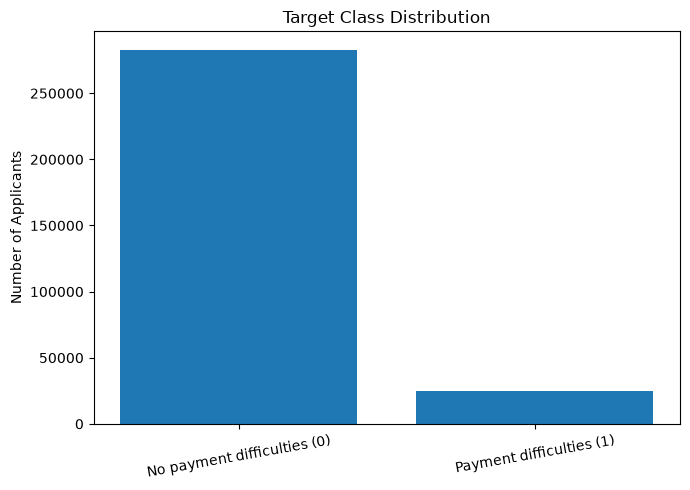

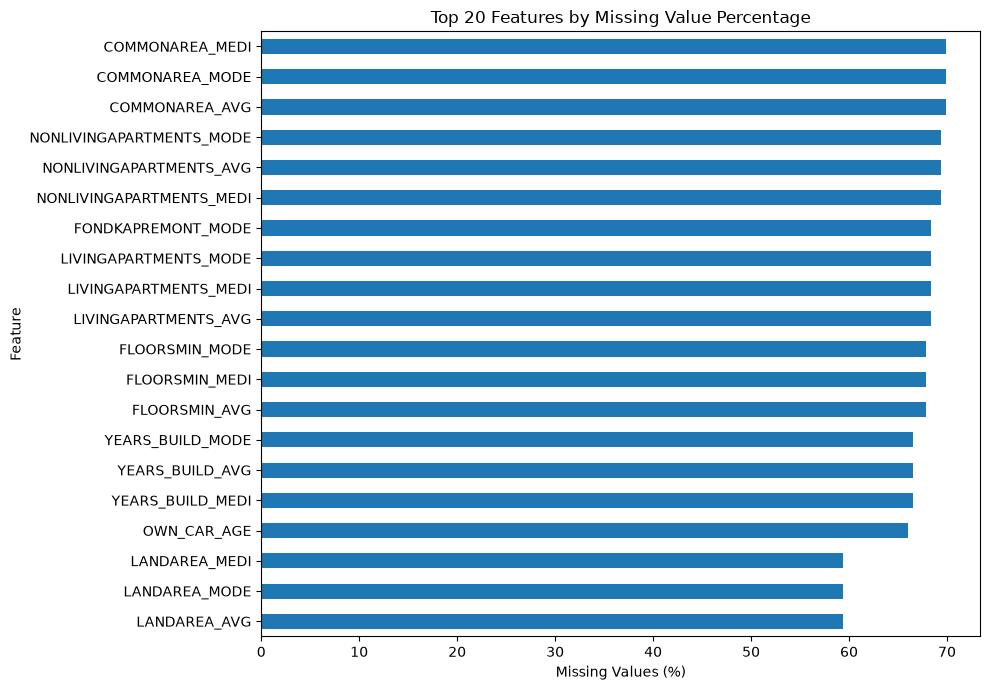

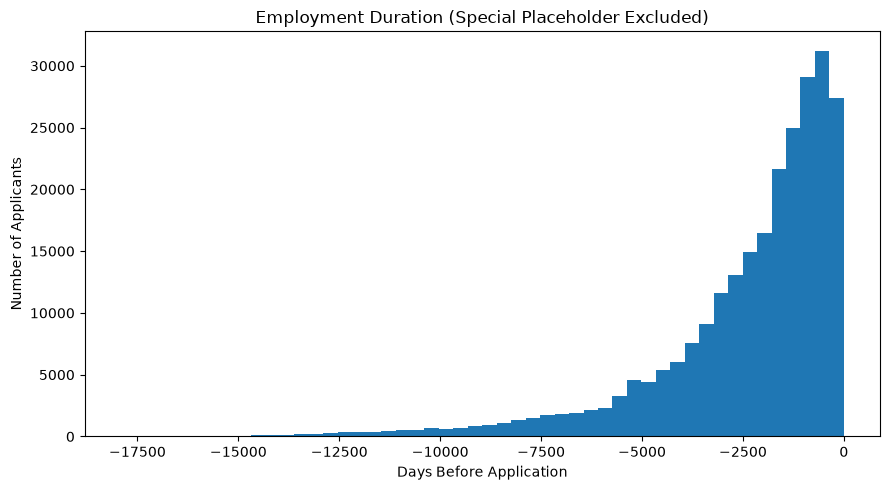


Special DAYS_EMPLOYED placeholder count: 55374
Special placeholder percentage: 18.01 %


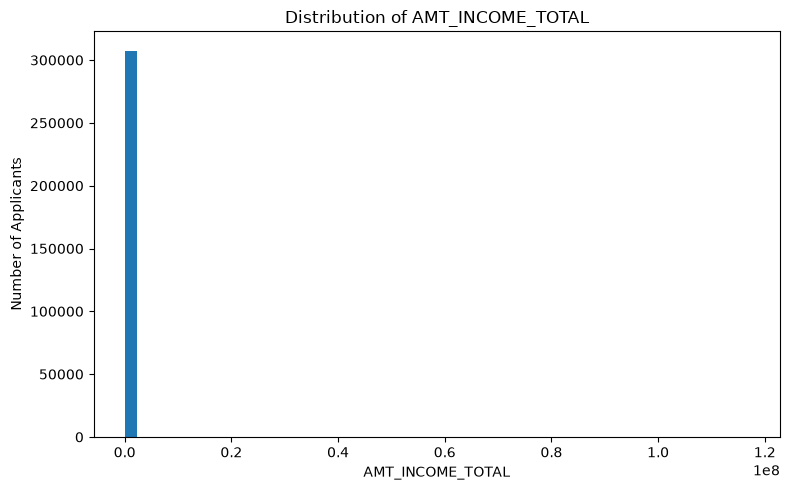

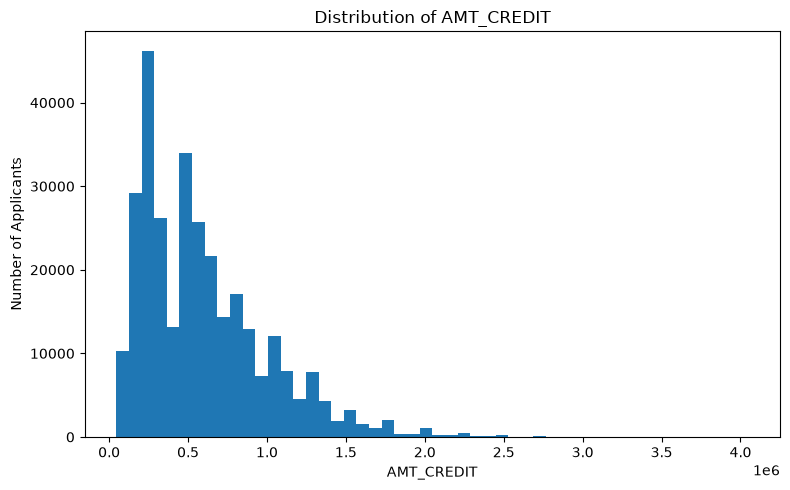

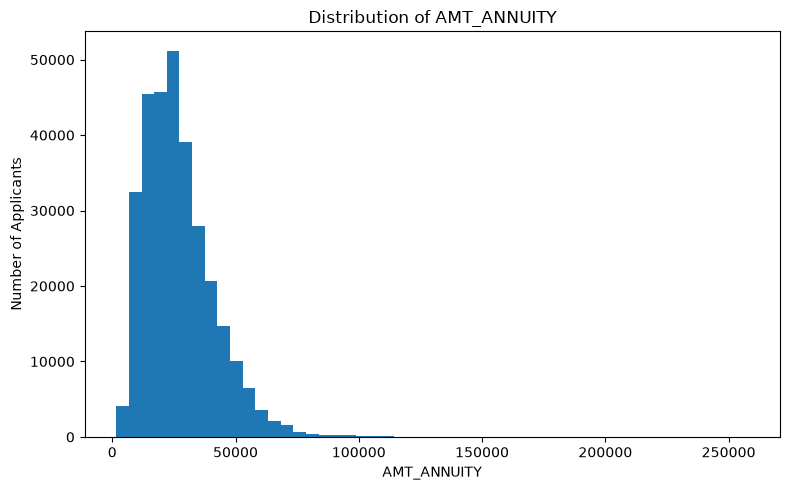

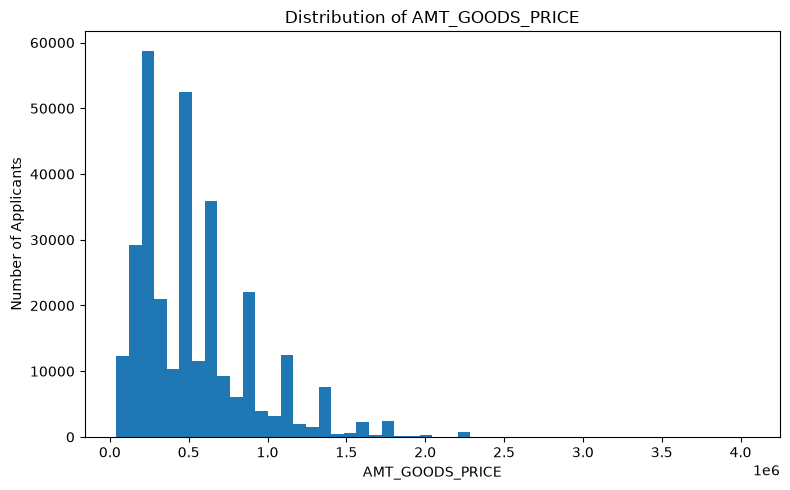


EDA visualizations saved in: ..\reports\figures

EDA visualization generation completed.


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Load dataset
DATA_PATH = Path("../data/raw/application_train.csv")
FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print("=" * 65)
print("RISKAEGIS - EXPLORATORY DATA ANALYSIS")
print("=" * 65)

# --------------------------------------------------
# 1. TARGET DISTRIBUTION
# --------------------------------------------------
target_counts = df["TARGET"].value_counts().sort_index()

plt.figure(figsize=(7, 5))
plt.bar(
    ["No payment difficulties (0)", "Payment difficulties (1)"],
    target_counts.values
)
plt.title("Target Class Distribution")
plt.ylabel("Number of Applicants")
plt.xticks(rotation=10)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "target_distribution.png", dpi=300)
plt.show()

# --------------------------------------------------
# 2. TOP 20 FEATURES WITH MISSING VALUES
# --------------------------------------------------
missing_percent = (
    df.drop(columns=["SK_ID_CURR", "TARGET"])
      .isnull()
      .mean()
      .mul(100)
      .sort_values(ascending=False)
      .head(20)
)

plt.figure(figsize=(10, 7))
missing_percent.sort_values().plot(kind="barh")
plt.title("Top 20 Features by Missing Value Percentage")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "missing_values.png", dpi=300)
plt.show()

# --------------------------------------------------
# 3. EMPLOYMENT DURATION
# --------------------------------------------------
SPECIAL_EMPLOYMENT_VALUE = 365243

special_count = (
    df["DAYS_EMPLOYED"] == SPECIAL_EMPLOYMENT_VALUE
).sum()

employment_days = df.loc[
    df["DAYS_EMPLOYED"] != SPECIAL_EMPLOYMENT_VALUE,
    "DAYS_EMPLOYED"
]

plt.figure(figsize=(9, 5))
plt.hist(employment_days, bins=50)
plt.title("Employment Duration (Special Placeholder Excluded)")
plt.xlabel("Days Before Application")
plt.ylabel("Number of Applicants")
plt.tight_layout()
plt.savefig(FIGURE_DIR / "employment_distribution.png", dpi=300)
plt.show()

print("\nSpecial DAYS_EMPLOYED placeholder count:", special_count)
print("Special placeholder percentage:",
      round(special_count / len(df) * 100, 2), "%")

# --------------------------------------------------
# 4. FINANCIAL FEATURE DISTRIBUTIONS
# --------------------------------------------------
financial_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

for feature in financial_features:
    plt.figure(figsize=(8, 5))
    plt.hist(df[feature].dropna(), bins=50)
    plt.title(f"Distribution of {feature}")
    plt.xlabel(feature)
    plt.ylabel("Number of Applicants")
    plt.tight_layout()

    plt.savefig(
        FIGURE_DIR / f"{feature.lower()}_distribution.png",
        dpi=300
    )
    plt.show()

print("\nEDA visualizations saved in:", FIGURE_DIR)
print("\nEDA visualization generation completed.")
print("=" * 65)


RISKAEGIS - FINANCIAL OUTLIER ANALYSIS

AMT_INCOME_TOTAL
Minimum: 25650.0
Median: 147150.0
95th percentile: 337500.0
99th percentile: 472500.0
Maximum: 117000000.0


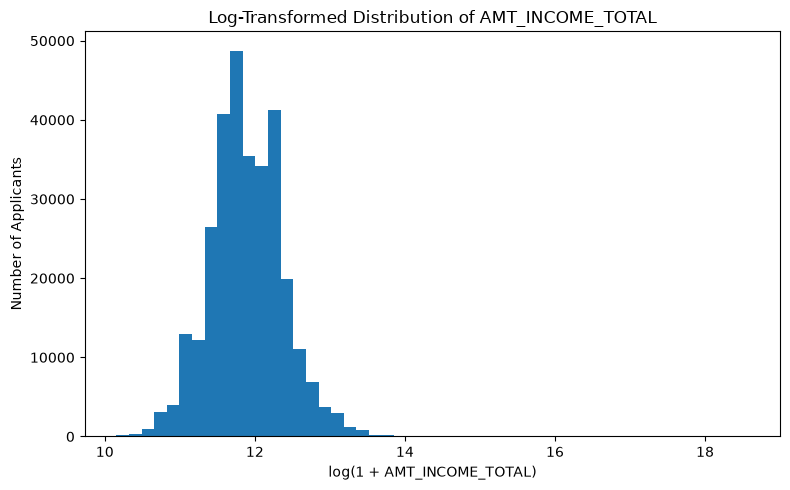


AMT_CREDIT
Minimum: 45000.0
Median: 513531.0
95th percentile: 1350000.0
99th percentile: 1854000.0
Maximum: 4050000.0


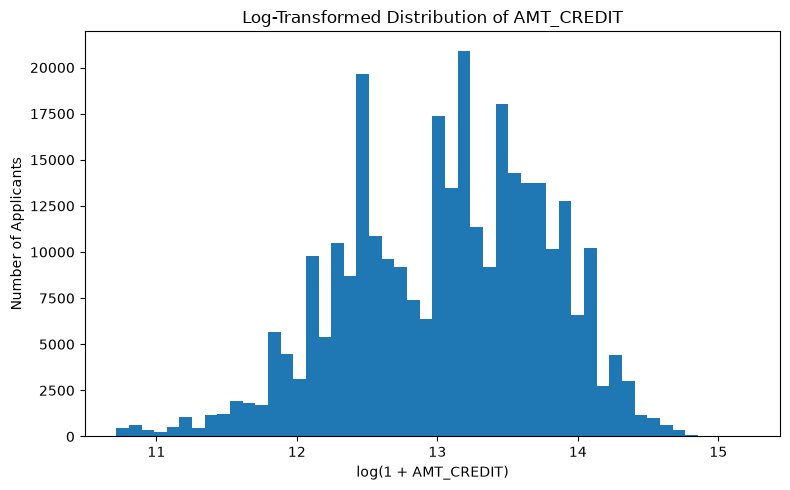


AMT_ANNUITY
Minimum: 1615.5
Median: 24903.0
95th percentile: 53325.0
99th percentile: 70006.5
Maximum: 258025.5


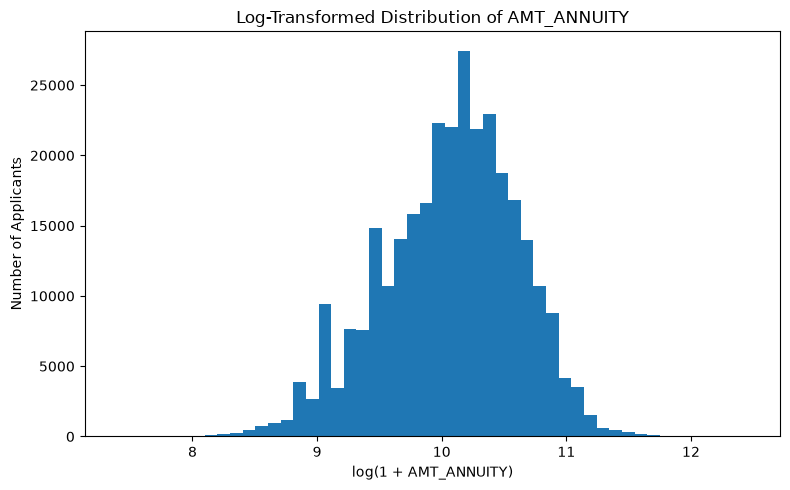


AMT_GOODS_PRICE
Minimum: 40500.0
Median: 450000.0
95th percentile: 1305000.0
99th percentile: 1800000.0
Maximum: 4050000.0


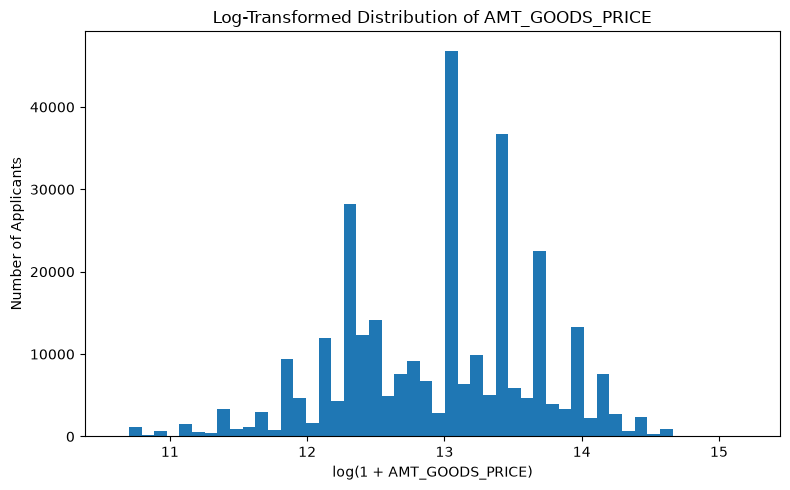


Financial outlier analysis completed.
Plots saved in: ..\reports\figures


In [10]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

FIGURE_DIR = Path("../reports/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

financial_features = [
    "AMT_INCOME_TOTAL",
    "AMT_CREDIT",
    "AMT_ANNUITY",
    "AMT_GOODS_PRICE"
]

print("=" * 60)
print("RISKAEGIS - FINANCIAL OUTLIER ANALYSIS")
print("=" * 60)

for feature in financial_features:

    values = df[feature].dropna()

    print(f"\n{feature}")
    print("Minimum:", values.min())
    print("Median:", values.median())
    print("95th percentile:", values.quantile(0.95))
    print("99th percentile:", values.quantile(0.99))
    print("Maximum:", values.max())

    # Log transformation for visualization only
    log_values = np.log1p(values)

    plt.figure(figsize=(8, 5))
    plt.hist(log_values, bins=50)

    plt.title(f"Log-Transformed Distribution of {feature}")
    plt.xlabel(f"log(1 + {feature})")
    plt.ylabel("Number of Applicants")

    plt.tight_layout()
    plt.savefig(
        FIGURE_DIR / f"{feature.lower()}_log_distribution.png",
        dpi=300
    )
    plt.show()

print("\nFinancial outlier analysis completed.")
print("Plots saved in:", FIGURE_DIR)
print("=" * 60)
